# Chapter 37 Through Probability

This is a companion to [`ch37_foundations_modern_physics.ipynb`](ch37_foundations_modern_physics.ipynb),
which simulates Millikan's oil drops and Rutherford's gold foil. Here the same two
experiments are written as **probability models with `sympy.stats`**, and every
formula is checked by simulation.

| § | Knight section | probability idea |
|---|---|---|
| 1 | 37.6 Discovery of the nucleus | **change of random variable**: uniform impact point → Rutherford's $1/\sin^4(\theta/2)$ |
| 2 | 37.6 Geiger–Marsden counting | **Poisson** rare events, and how many alphas you need |
| 3 | 37.5 Fundamental unit of charge | **error propagation** by log-differentiation; when quantization becomes unreadable |

Module: [`dgs/ch37_probability.py`](../dgs/ch37_probability.py).

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from IPython.display import display, Math
from dgs.ch37_probability import (
    theta, bmax, rutherford_theta_pdf, rutherford_from_cross_section, theta_min,
    tail_probability, sample_theta, alphas_needed, poisson_at_least_one_symbolic,
    poisson_mean_var_symbolic, millikan_relative_sigma_symbolic, millikan_relative_sigma,
    millikan_mc_relative_sigma, misassignment_probability, misassignment_symbolic,
)

# 1. Rutherford scattering is a change of random variable

An alpha particle aimed at a gold foil hits a **random point** of a small disc
(radius $b_\max$) around a nucleus. The distance $b$ from the center, the *impact
parameter*, is a random variable with density $f_b(b) = 2b/b_\max^2$, because
there's more area at larger radius.

Coulomb repulsion turns each $b$ into a deflection angle. Measuring lengths in
units of the closest-approach distance $d$, $\theta = 2\arctan\frac{1}{2b}$.

**The change-of-variables rule** $f_\theta(\theta) = f_b\big(b(\theta)\big)\left|\frac{db}{d\theta}\right|$
gives the distribution of angles. SymPy carries it out, and the result matches
Rutherford's cross-section formula $\frac{d\sigma}{d\Omega} \propto \frac{1}{\sin^4(\theta/2)}$
times the solid-angle factor $2\pi\sin\theta$:

In [2]:
f = rutherford_theta_pdf(); g = rutherford_from_cross_section()
display(Math(r"f_\theta \text{ (change of variables)} = " + sp.latex(f)))
display(Math(r"\frac{1}{\pi b_{max}^2}\frac{d\sigma}{d\Omega}\,2\pi\sin\theta = " + sp.latex(g)))
print("difference simplifies to:", sp.simplify(f - g))
B = 20.0
print("normalization ∫ f dθ from θ_min to π =", float(sp.integrate(f.subs(bmax, B), (theta, theta_min(B), sp.pi))))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

difference simplifies to: 0


normalization ∫ f dθ from θ_min to π = 1.0


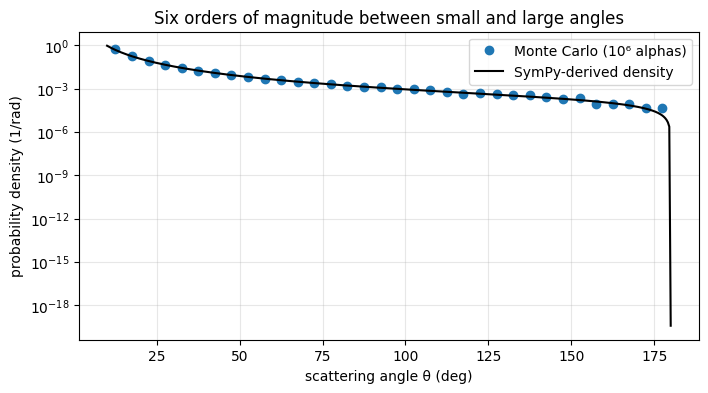

P(θ >  30°): formula cot²(T/2)/(4 b_max²) = 0.008705,  simulation 0.008636
P(θ >  90°): formula cot²(T/2)/(4 b_max²) = 0.000625,  simulation 0.000663
P(θ > 150°): formula cot²(T/2)/(4 b_max²) = 0.000045,  simulation 0.000049


In [3]:
th = sample_theta(1_000_000, B, seed=37)
edges = np.radians(np.arange(10, 181, 5)); centers = (edges[:-1] + edges[1:])/2
counts, _ = np.histogram(th, bins=edges)
pdf = sp.lambdify(theta, f.subs(bmax, B), "numpy")
fig, ax = plt.subplots(figsize=(8, 4))
ax.semilogy(np.degrees(centers), counts/(len(th)*np.diff(edges)), "o", label="Monte Carlo (10⁶ alphas)")
tt = np.linspace(edges[0], np.pi, 400)
ax.semilogy(np.degrees(tt), pdf(tt), "k", label="SymPy-derived density")
ax.set(xlabel="scattering angle θ (deg)", ylabel="probability density (1/rad)",
       title="Six orders of magnitude between small and large angles"); ax.legend(); ax.grid(alpha=0.3, which="both"); plt.show()
for T in (30, 90, 150):
    print(f"P(θ > {T:3d}°): formula cot²(T/2)/(4 b_max²) = {float(tail_probability(np.radians(T), B)):.6f},  "
          f"simulation {np.mean(th > np.radians(T)):.6f}")

# 2. Rare events are Poisson: how many alphas do you need?

Geiger and Marsden reported that roughly 1 alpha in 8,000 bounced back from a
gold foil. If each alpha backscatters independently with probability $p$, the count
in $n$ alphas is approximately $K \sim \text{Poisson}(\lambda = np)$, with mean and
variance both equal to $\lambda$. To see at least one event with 95% confidence:

In [4]:
display(Math(r"P(K \ge 1) = " + sp.latex(poisson_at_least_one_symbolic())))
mean, var = poisson_mean_var_symbolic()
display(Math(r"E[K] = " + sp.latex(mean) + r",\quad \operatorname{Var}[K] = " + sp.latex(var)))
p = 1/8000
for c in (0.5, 0.9, 0.95, 0.99):
    print(f"confidence {c:.2f}: need n = {alphas_needed(p, c):6d} alphas  (≈ {alphas_needed(p, c)*p:.2f}/p)")
print("\n95% → n ≈ 3/p: the 'rule of three' used to set limits on rare events")

<IPython.core.display.Math object>

<IPython.core.display.Math object>

confidence 0.50: need n =   5546 alphas  (≈ 0.69/p)
confidence 0.90: need n =  18421 alphas  (≈ 2.30/p)
confidence 0.95: need n =  23966 alphas  (≈ 3.00/p)
confidence 0.99: need n =  36842 alphas  (≈ 4.61/p)

95% → n ≈ 3/p: the 'rule of three' used to set limits on rare events


Geiger and Marsden counted scintillation flashes by eye in a dark room, so every
extra alpha cost observing time. The Poisson model says how much data a claim
needs. The relative uncertainty after $K$ counts is $1/\sqrt{K}$, so 100 backscatter
events pin the rate down to about ±10%.

# 3. Millikan: error propagation and the limit of quantization

The charge on a drop is $q = mgd/V$, with the mass from Stokes' law and the fall
speed $v$: $m \propto r^3 \propto v^{3/2}$. So $q \propto v^{3/2}/V$.
**Log-differentiation** turns the product into a sum, which gives the propagated
error directly:

$$\ln q = \tfrac32\ln v - \ln V + \text{const}\;\Rightarrow\;
\frac{\sigma_q}{q} = \sqrt{\Big(\tfrac32\frac{\sigma_v}{v}\Big)^2 + \Big(\frac{\sigma_V}{V}\Big)^2}$$

The fall speed counts **1.5 times** as much as the voltage.

<IPython.core.display.Math object>

2% speed noise, 0.5% voltage noise → σ_q/q = 0.0304 (formula),  0.0305 (Monte Carlo)


<IPython.core.display.Math object>

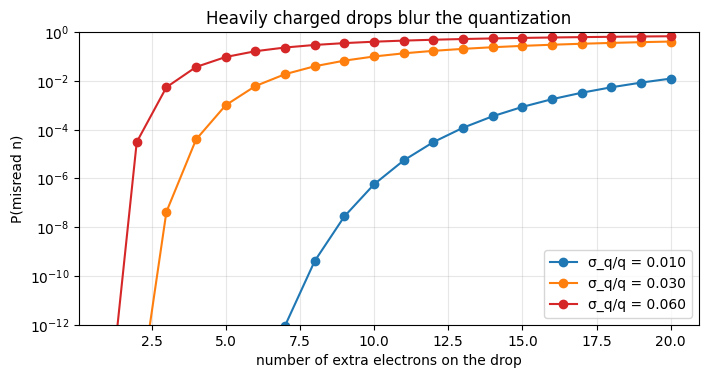

n =  1: P(misread) = 9.91e-61
n =  5: P(misread) = 1.01e-03
n = 10: P(misread) = 1.00e-01


In [5]:
display(Math(r"\frac{\sigma_q}{q} = " + sp.latex(millikan_relative_sigma_symbolic())))
rel = millikan_relative_sigma(0.02, 0.005)
print(f"2% speed noise, 0.5% voltage noise → σ_q/q = {rel:.4f} (formula),  {millikan_mc_relative_sigma(0.02, 0.005):.4f} (Monte Carlo)")
s = sp.Symbol("s", positive=True)
display(Math(r"P(\text{wrong integer}) = P(|X| > \tfrac12),\; X\sim N(0,s):\quad " + sp.latex(misassignment_symbolic())))
n = np.arange(1, 21)
fig, ax = plt.subplots(figsize=(8, 3.8))
for r_, col in ((0.01, "C0"), (rel, "C1"), (0.06, "C3")):
    ax.semilogy(n, misassignment_probability(n, r_), "o-", color=col, label=f"σ_q/q = {r_:.3f}")
ax.set(xlabel="number of extra electrons on the drop", ylabel="P(misread n)", ylim=(1e-12, 1),
       title="Heavily charged drops blur the quantization"); ax.legend(); ax.grid(alpha=0.3, which="both"); plt.show()
for k in (1, 5, 10):
    print(f"n = {k:2d}: P(misread) = {float(misassignment_probability(k, rel)):.2e}")

With 3% charge noise, a drop carrying 1 extra electron is read correctly almost
always. One carrying 10 is misread 10% of the time. **The quantization of charge is
only visible for lightly charged drops**, which is why Millikan's method
concentrates on them, and why the existing Ch. 37 notebook simulates drops with
1–5 electrons.

## Exercises
1. Use `sympy.stats` to find the *median* deflection angle for $b_\max = 20$.
2. If the foil is twice as thick (two nuclei per disc area), how do the probabilities in §1 and §2 change?
3. Millikan measured fall times, not speeds: $v = L/t$. Redo §3 with $\sigma_t/t$ instead of $\sigma_v/v$.
4. Show that the Poisson approximation to Binomial$(n, p)$ is excellent here by comparing $P(K \ge 1)$ both ways for $n = 24{,}000$.